In [8]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import os
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import sys
import json
sys.path.append('..')
from script.utils.weights import organism_loss_weights
from script.utils.metrics import psmae, psmse

In [9]:


def analyze_predictions(data: pd.DataFrame, use_weights = True):
    results = pd.DataFrame(columns=["R2", "MAE", "MSE", "RMSE", "PSMAE", "PSMSE", "PSRMSE"])
    for split in sorted(data.split_number.unique()):
        subdata = data[data.split_number.eq(split)]
        weights = None
        if use_weights:
            weights = organism_loss_weights(subdata.target_organism)
        y_real = subdata.real_pIC50
        y_pred = subdata.pred_pIC50
        r2=r2_score(y_real, y_pred, sample_weight=weights)
        mae= mean_absolute_error(y_real, y_pred, sample_weight=weights)
        mse=mean_squared_error(y_real, y_pred, sample_weight=weights)
        rmse=mse**0.5
        pmsae=psmae(y_real, y_pred, subdata.target_organism, weights)
        pmsse=psmse(y_real, y_pred, subdata.target_organism, weights)
        results.loc[f"Split {split}"] = [r2, mae, mse, rmse, pmsae, pmsse, pmsse**.5]

    return {col: {"mean":results[col].mean(), "std":results[col].std()} for col in results.columns}

results, wresults = {}, {}
for file in os.walk("."):
    if "predictions.csv" in file[2]:
        data = pd.read_csv(file[0]+"/predictions.csv")
        results[file[0][2:]] = analyze_predictions(data, False)
        wresults[file[0][2:]] = analyze_predictions(data, True)
metrics_df = pd.DataFrame(results).transpose().sort_index()
wmetrics_df = pd.DataFrame(wresults).transpose().sort_index()
wmetrics_df.columns = ["w" + col for col in wmetrics_df.columns]
metrics_df = pd.concat([metrics_df, wmetrics_df], axis=1)
metrics_df = pd.concat(
    {col: metrics_df[col].apply(pd.Series) for col in metrics_df.columns},
    axis=1
)
metrics_df.round(4).iloc[:,:14]

R2             MAE             MSE          \
                              mean     std    mean     std    mean     std   
01_model                    0.4423  0.0470  0.3647  0.0270  0.2698  0.0370   
02_ablation_only_molformer  0.3825  0.0619  0.3908  0.0274  0.2991  0.0468   
03_ablation_only_moldesc    0.4359  0.0753  0.3793  0.0301  0.2727  0.0463   
04_no_film                  0.4240  0.0459  0.3814  0.0251  0.2791  0.0416   
05_no_organism_info         0.3459  0.0659  0.4204  0.0275  0.3166  0.0504   
06_model_by_species         0.4297  0.0544  0.3811  0.0273  0.2763  0.0452   
07_baseline_xgb             0.4049  0.0561  0.3893  0.0299  0.2886  0.0479   
10_hugeMLP                  0.4214  0.0386  0.3704  0.0247  0.2807  0.0424   

                              RMSE           PSMAE           PSMSE          \
                              mean     std    mean     std    mean     std   
01_model                    0.5183  0.0356  0.5580  0.0308  0.3979  0.0368   
02_ablation_only_molformer  0.5454  0.0426  0.6001  0.0274  0.4428  0.0468   
03_ablation_only_moldesc    0.5206  0.0435  0.5852  0.0399  0.4095  0.0576   
04_no_film                  0.5270  0.0390  0.5851  0.0228  0.4132  0.0361   
05_no_organism_info         0.5612  0.0435  0.6424  0.0311  0.4680  0.0522   
06_model_by_species         0.5242  0.0420  0.5883  0.0304  0.4129  0.0435   
07_baseline_xgb             0.5356  0.0436  0.5970  0.0306  0.4279  0.0483   
10_hugeMLP                  0.5285  0.0402  0.5670  0.0239  0.4149  0.0383   

                            PSRMSE          
                              mean     std  
01_model                    0.6302  0.0292  
02_ablation_only_molformer  0.6646  0.0351  
03_ablation_only_moldesc    0.6385  0.0442  
04_no_film                  0.6422  0.0279  
05_no_organism_info         0.6832  0.0375  
06_model_by_species         0.6418  0.0335  
07_baseline_xgb             0.6532  0.0366  
10_hugeMLP                  0.6435  0.0301

In [10]:
metrics_df.round(4).iloc[:,14:]

wR2            wMAE            wMSE          \
                              mean     std    mean     std    mean     std   
01_model                    0.4943  0.0699  0.3268  0.0282  0.2206  0.0474   
02_ablation_only_molformer  0.4181  0.0771  0.3571  0.0303  0.2548  0.0608   
03_ablation_only_moldesc    0.4184  0.1032  0.3599  0.0274  0.2519  0.0514   
04_no_film                  0.4611  0.0568  0.3445  0.0278  0.2365  0.0545   
05_no_organism_info         0.4280  0.0886  0.3643  0.0293  0.2496  0.0573   
06_model_by_species         0.4071  0.1070  0.3700  0.0377  0.2613  0.0787   
07_baseline_xgb             0.3943  0.0593  0.3664  0.0309  0.2663  0.0627   
10_hugeMLP                  0.4663  0.0740  0.3326  0.0316  0.2347  0.0619   

                             wRMSE          wPSMAE          wPSMSE          \
                              mean     std    mean     std    mean     std   
01_model                    0.4674  0.0487  0.5616  0.0437  0.3535  0.0479   
02_ablation_only_molformer  0.5019  0.0563  0.6153  0.0455  0.4093  0.0548   
03_ablation_only_moldesc    0.4997  0.0492  0.6246  0.0702  0.4157  0.0777   
04_no_film                  0.4836  0.0540  0.5928  0.0380  0.3793  0.0484   
05_no_organism_info         0.4969  0.0551  0.6244  0.0497  0.4006  0.0631   
06_model_by_species         0.5065  0.0727  0.6406  0.0560  0.4234  0.0789   
07_baseline_xgb             0.5131  0.0582  0.6281  0.0355  0.4267  0.0572   
10_hugeMLP                  0.4811  0.0603  0.5699  0.0371  0.3751  0.0601   

                           wPSRMSE          
                              mean     std  
01_model                    0.5933  0.0400  
02_ablation_only_molformer  0.6386  0.0414  
03_ablation_only_moldesc    0.6423  0.0591  
04_no_film                  0.6148  0.0384  
05_no_organism_info         0.6313  0.0489  
06_model_by_species         0.6483  0.0591  
07_baseline_xgb             0.6520  0.0427  
10_hugeMLP                  0.6108  0.0473

In [11]:
results = {}

for organism in (organisms:=data.target_organism.value_counts().index):
    results[organism] = {}
    for file in sorted(os.walk(".")):
        if "predictions.csv" in file[2]:
            experiment = file[0][2:]
            results[organism][experiment] = []
            exp_data = pd.read_csv(file[0]+"/predictions.csv")
            exp_data = exp_data[exp_data.target_organism.eq(organism)]
            for partition in range(10):
                subdata = exp_data[exp_data.split_number.eq(partition)]
                results[organism][experiment].append(r2_score(subdata["real_pIC50"], subdata["pred_pIC50"]))

_results_df = pd.DataFrame(results)
results_df = pd.concat(
    {
        col: pd.DataFrame({
            "mean": _results_df[col].apply(np.mean),
            "std": _results_df[col].apply(np.std)
        })
        for col in _results_df.columns
    }, axis=1
)
results_df.columns.names = ["organism", "R²"]
results_df.index.name = "model"

results_df.round(3)

organism                   Staphylococcus aureus         \
R²                                          mean    std   
model                                                     
01_model                                   0.398  0.091   
02_ablation_only_molformer                 0.386  0.111   
03_ablation_only_moldesc                   0.441  0.074   
04_no_film                                 0.401  0.059   
05_no_organism_info                        0.270  0.082   
06_model_by_species                        0.473  0.069   
07_baseline_xgb                            0.426  0.085   
10_hugeMLP                                 0.393  0.093   

organism                   Salmonella enterica subsp. enterica serovar Typhimurium  \
R²                                                                            mean   
model                                                                                
01_model                                                                0.350        
02_ablation_only_molformer                                              0.251        
03_ablation_only_moldesc                                                0.366        
04_no_film                                                              0.326        
05_no_organism_info                                                     0.218        
06_model_by_species                                                     0.316        
07_baseline_xgb                                                         0.332        
10_hugeMLP                                                              0.319        

organism                          Escherichia coli         \
R²                            std             mean    std   
model                                                       
01_model                    0.066            0.564  0.154   
02_ablation_only_molformer  0.111            0.482  0.234   
03_ablation_only_moldesc    0.090            0.507  0.175   
04_no_film                  0.074            0.529  0.169   
05_no_organism_info         0.059            0.467  0.160   
06_model_by_species         0.074            0.517  0.163   
07_baseline_xgb             0.066            0.462  0.193   
10_hugeMLP                  0.068            0.550  0.177   

organism                   Streptococcus mutans         \
R²                                         mean    std   
model                                                    
01_model                                  0.139  0.345   
02_ablation_only_molformer               -0.031  0.485   
03_ablation_only_moldesc                  0.150  0.434   
04_no_film                                0.115  0.409   
05_no_organism_info                       0.239  0.424   
06_model_by_species                       0.109  0.400   
07_baseline_xgb                          -0.047  0.599   
10_hugeMLP                                0.019  0.386   

organism                   Mycolicibacterium smegmatis         \
R²                                                mean    std   
model                                                           
01_model                                         0.444  0.254   
02_ablation_only_molformer                       0.358  0.328   
03_ablation_only_moldesc                         0.401  0.249   
04_no_film                                       0.405  0.237   
05_no_organism_info                              0.384  0.241   
06_model_by_species                              0.330  0.306   
07_baseline_xgb                                  0.370  0.305   
10_hugeMLP                                       0.417  0.273   

organism                   Bacillus subtilis        Pseudoalteromonas ulvae  \
R²                                      mean    std                    mean   
model                                                                         
01_model                               0.436  0.143                   0.376   
02_ablation_only_molformer             0.328  0.175         

In [12]:
results = {}

for organism in data.target_organism.value_counts().index:
    results[organism] = {}
    for file in sorted(os.walk(".")):
        if "predictions.csv" in file[2]:
            experiment = file[0][2:]
            results[organism][experiment] = []
            exp_data = pd.read_csv(file[0]+"/predictions.csv")
            exp_data = exp_data[exp_data.target_organism.eq(organism)]
            for partition in range(10):
                subdata = exp_data[exp_data.split_number.eq(partition)]
                results[organism][experiment].append(np.sqrt(mean_squared_error(subdata["real_pIC50"], subdata["pred_pIC50"])))

_results_df = pd.DataFrame(results)
results_df = pd.concat(
    {
        col: pd.DataFrame({
            "mean": _results_df[col].apply(np.mean),
            "std": _results_df[col].apply(np.std)
        })
        for col in _results_df.columns
    }, axis=1
)

results_df.columns.names = ["organism", "RMSE"]
results_df.index.name = "model"

results_df


organism                   Staphylococcus aureus            \
RMSE                                        mean       std   
model                                                        
01_model                                0.554500  0.070957   
02_ablation_only_molformer              0.559856  0.081456   
03_ablation_only_moldesc                0.533350  0.052371   
04_no_film                              0.553635  0.059814   
05_no_organism_info                     0.608562  0.043692   
06_model_by_species                     0.518424  0.054619   
07_baseline_xgb                         0.541378  0.066592   
10_hugeMLP                              0.556829  0.072781   

organism                   Salmonella enterica subsp. enterica serovar Typhimurium  \
RMSE                                                                          mean   
model                                                                                
01_model                                                             0.552802        
02_ablation_only_molformer                                           0.592727        
03_ablation_only_moldesc                                             0.545199        
04_no_film                                                           0.562571        
05_no_organism_info                                                  0.606144        
06_model_by_species                                                  0.566631        
07_baseline_xgb                                                      0.560980        
10_hugeMLP                                                           0.565274        

organism                             Escherichia coli            \
RMSE                             std             mean       std   
model                                                             
01_model                    0.047665         0.453839  0.081586   
02_ablation_only_molformer  0.061579         0.486984  0.104784   
03_ablation_only_moldesc    0.056217         0.481035  0.061746   
04_no_film                  0.047098         0.470863  0.084116   
05_no_organism_info         0.043738         0.503759  0.080360   
06_model_by_species         0.044690         0.480889  0.086059   
07_baseline_xgb             0.055374         0.508658  0.110247   
10_hugeMLP                  0.042775         0.459442  0.090635   

organism                   Streptococcus mutans            \
RMSE                                       mean       std   
model                                                       
01_model                               0.527393  0.140311   
02_ablation_only_molformer             0.566657  0.115835   
03_ablation_only_moldesc               0.510928  0.105939   
04_no_film                             0.524686  0.110428   
05_no_organism_info                    0.481006  0.105535   
06_model_by_species                    0.528153  0.092819   
07_baseline_xgb                        0.565540  0.101423   
10_hugeMLP                             0.561464  0.116770   

organism                   Mycolicibacterium smegmatis            \
RMSE                                              mean       std   
model                                                              
01_model                                      0.236219  0.031873   
02_ablation_only_molformer                    0.253851  0.029681   
03_ablation_only_moldesc                      0.247269  0.035126   
04_no_film                                    0.246863  0.032207   
05_no_organism_info                           0.252287  0.033080   
06_model_by_species                           0.260137  0.049232   
07_baseline_xgb                               0.252112  0.041817   
10_hugeMLP                                    0.242242  0.037560   

organism                   Bacillus subtilis            \
RMSE                                    mean       std   
model                                                    
01_model                            0

In [13]:
for organism in data.target_organism.unique():
    print(organism)
    results = {}
    for file in os.walk("."):
        if "predictions.csv" in file[2]:
            data = pd.read_csv(file[0]+"/predictions.csv")
            data = data[data.target_organism.eq(organism)]
            results[file[0][2:]] = analyze_predictions(data, True)
    metrics_df = pd.DataFrame(results).transpose().sort_index()
    metrics_df = pd.concat(
        {col: metrics_df[col].apply(pd.Series) for col in metrics_df.columns},
        axis=1
    )
    print(metrics_df.round(4))

Staphylococcus aureus
                                R2             MAE             MSE          \
                              mean     std    mean     std    mean     std   
01_model                    0.3978  0.0963  0.3974  0.0425  0.3125  0.0830   
02_ablation_only_molformer  0.3864  0.1165  0.4013  0.0476  0.3201  0.0947   
03_ablation_only_moldesc    0.4410  0.0781  0.4021  0.0466  0.2872  0.0578   
04_no_film                  0.4008  0.0617  0.4076  0.0399  0.3101  0.0706   
05_no_organism_info         0.2699  0.0861  0.4654  0.0392  0.3723  0.0574   
06_model_by_species         0.4728  0.0723  0.3879  0.0421  0.2717  0.0575   
07_baseline_xgb             0.4260  0.0894  0.4013  0.0488  0.2975  0.0718   
10_hugeMLP                  0.3928  0.0980  0.3979  0.0372  0.3154  0.0855   

                              RMSE           PSMAE           PSMSE          \
                              mean     std    mean     std    mean     std   
01_model                    0.5545  0.074

In [14]:
together_df = None

for file in sorted(os.walk(".")):
    if "predictions.csv" in file[2]:
        data = pd.read_csv(file[0]+"/predictions.csv").iloc[:,1:]
        data.set_index(["split_number", "target_organism", "curated_smiles"], inplace=True)
        colname = file[0][2:]
        data.rename(columns={"pred_pIC50": colname}, inplace=True)
        if together_df is None:
            together_df = data
        else:
            together_df[colname] = data[colname]

together_df.reset_index(inplace=True)
together_df.head()

,split_number,target_organism,curated_smiles,real_pIC50,01_model,02_ablation_only_molformer,03_ablation_only_moldesc,04_no_film,05_no_organism_info,06_model_by_species,07_baseline_xgb,10_hugeMLP
0,0,Staphylococcus aureus,COc1cc([C@H]2Oc3ccc(C4Oc5cc(O)cc(O)c5C(=O)C4O)...,4.178294,4.262976,4.532147,4.293309,4.439983,4.731791,4.433229,4.824485,3.974819
1,0,Staphylococcus aureus,CCOC(=O)Cn1nc(-n2cc(COc3cc(C(F)(F)F)[nH]c(=N)n...,5.134338,5.008428,5.144083,5.005244,4.936426,5.250769,5.061416,4.987695,5.215132
2,0,Escherichia coli,COC(=O)c1cccc(-c2ccc(O[C@H]3O[C@H](CO)[C@@H](O...,6.050610,6.157995,6.408064,6.094454,6.307707,6.040329,6.231472,6.727011,6.219728
3,0,Pseudoalteromonas ulvae,COc1ccc(CCNC(=O)c2cn(-c3cccc(OC)c3)nn2)cc1,4.943095,4.532205,4.655389,4.337159,4.534808,4.366167,4.729002,4.426260,4.653427
4,0,Staphylococcus aureus,N=c1[nH]cc(-c2ccc(NC(=O)c3cc4ccccc4[nH]3)cc2)[...,4.045757,4.169370,4.252699,4.185678,4.195133,4.215087,4.038517,4.008945,4.118151


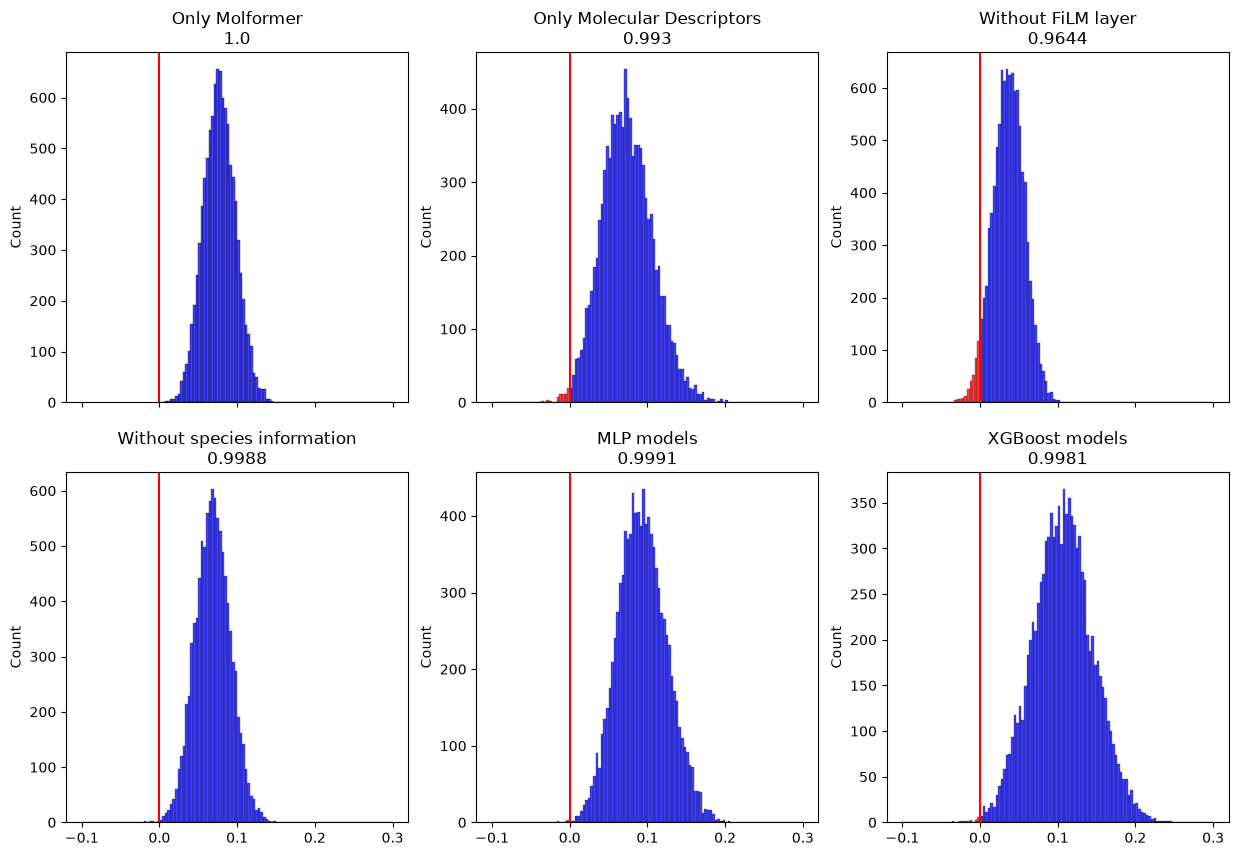

In [17]:



def paired_bootstrap_r2(df, pred_a, pred_b, n_boot=10_000, seed=42):
    rng = np.random.default_rng(seed)

    y = df["real_pIC50"].to_numpy()
    pred_a = df[pred_a].to_numpy()
    pred_b = df[pred_b].to_numpy()
    organisms = df["target_organism"].to_numpy()
    weights = organism_loss_weights(organisms)
    blocks = list(
        df.groupby("curated_smiles", sort=False).indices.values()
    )

    def difference(idx):
        rmse_a = r2_score(y[idx], pred_a[idx], sample_weight=weights[idx])
        rmse_b = r2_score(y[idx], pred_b[idx], sample_weight=weights[idx])
        return rmse_a - rmse_b

    deltas = np.empty(n_boot)

    for b in range(n_boot):
        sampled = rng.integers(0, len(blocks), size=len(blocks))
        idx = np.concatenate([blocks[j] for j in sampled])
        deltas[b] = difference(idx)

    return deltas

fig, axes = plt.subplots(2,3, figsize=(15,10), sharex=True)
model_names = ["Only Molformer", "Only Molecular Descriptors", "Without FiLM layer", "Without species information", "MLP models", "XGBoost models"]

for i,col in enumerate(together_df.columns[5:]):
    if i==6:
        break
    deltas = paired_bootstrap_r2(together_df, "01_model", col)
    dl = deltas[np.where(deltas<0)]
    dh = deltas[np.where(deltas>0)]
    ax = axes[i//3][i%3]
    sns.histplot(dl, ax=ax, color="red", bins=30, binrange=(-0.1,0), )

    sns.histplot(dh, ax=ax, color="blue", bins=90, binrange=(0,0.3))
    ax.axvline(ymax=500, color="red")
    ax.set_title(model_names[i] + "\n" + str(sum(deltas>0)/len(deltas)))

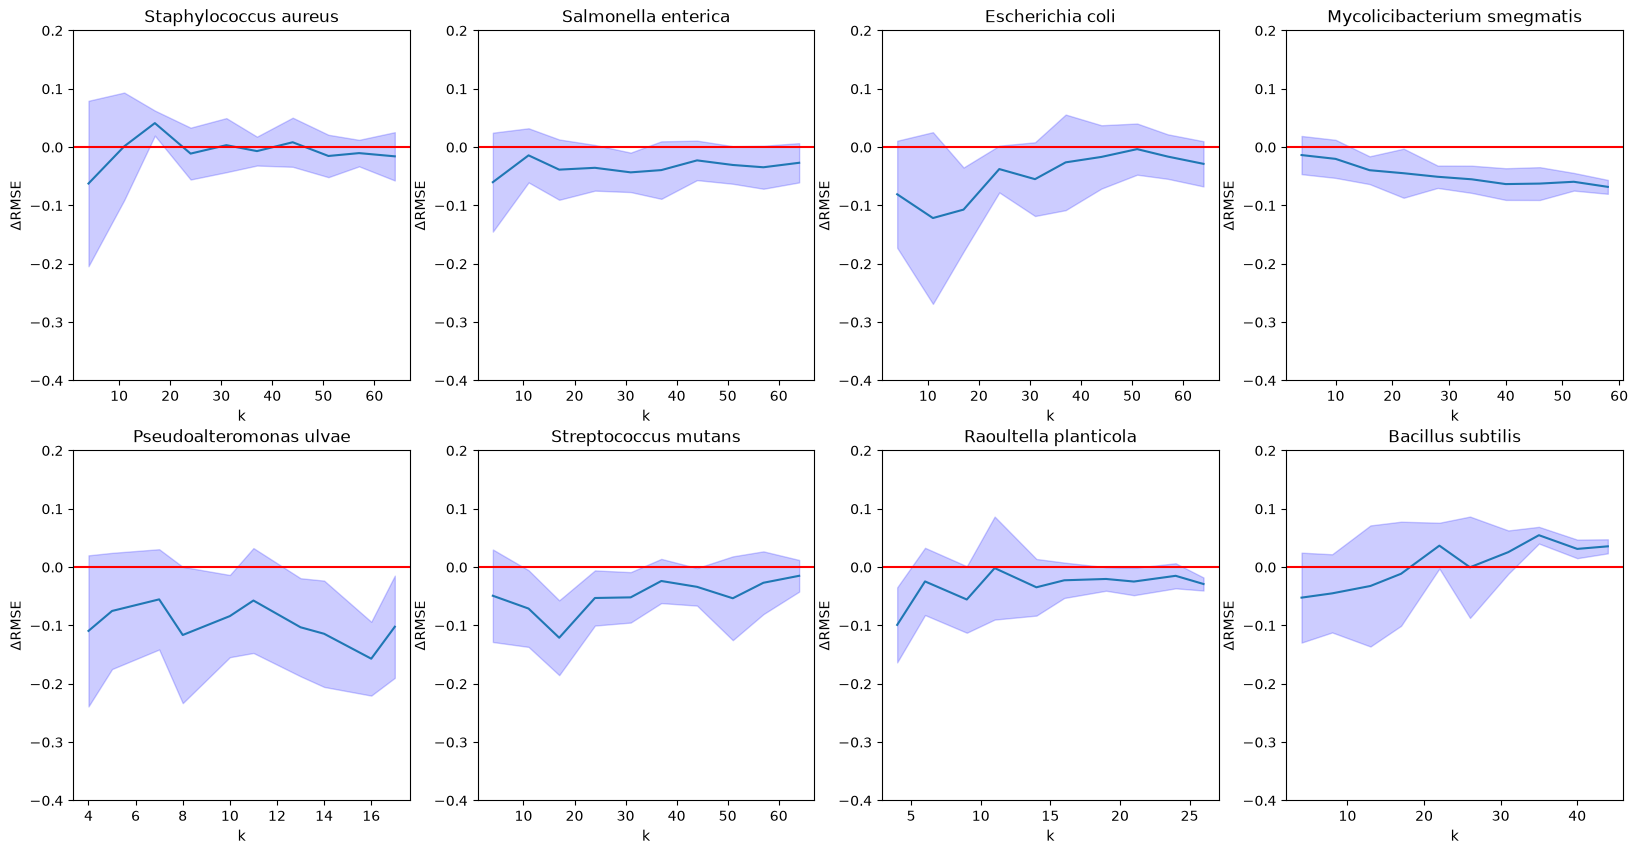

In [18]:
fig, axes = plt.subplots(2, 4, figsize = (20,10))

with open("08_few_shots/results.json", "r") as file:
    few_shots_data = json.load(file)


for i, species in enumerate(few_shots_data):

    ax = axes[i//4, i%4]

    sa_data = few_shots_data[species]
    sa_results = {}
    for k, results in sa_data.items():
        differences = [r["difference"] for r in results.values()]
        sa_results[int(k)] = {"mean": np.mean(differences), "std":np.std(differences)}

    sa_data = pd.DataFrame(sa_results).T.reset_index().rename(columns={"index":"k"})

    lower = sa_data["mean"] - sa_data["std"]
    upper = sa_data["mean"] + sa_data["std"]

    sns.lineplot(sa_data, x="k", y="mean", ax=ax)
    ax.fill_between(sa_data.k, lower, upper, alpha=.2, color="b")
    ax.set_ylim(-0.4, 0.2)
    ax.axhline(xmax=64, color="red")
    ax.set_ylabel("ΔRMSE")
    ax.set_title("Salmonella enterica" if species.startswith("Salmonella") else species)